# Credit Card Fraud Detection with Random Forest

### Looking beyond accuracy when fraud is rare

When fraud makes up only a tiny share of transactions, a model can look excellent on accuracy and still miss the cases that matter. I wanted to find out whether a Random Forest could catch a useful share of fraud without generating too many false alarms.

I compare it with a **Logistic Regression baseline**, focusing on precision, recall, average precision (AP), and the actual number of mistakes. I choose an illustrative alert threshold using **validation data**, then check the result once on a held-out test set.

The workflow is: **inspect the data → split → explore the training set → fit models → compare → choose a threshold → test**.

> **Scope:** This is a learning and portfolio project, not a production fraud detection system. The saved results come from a run on the original dataset. To reproduce them, download `creditcard.csv` and run the notebook from the beginning.


## 1. Dataset, provenance, and research question

**Dataset:** [Credit Card Fraud Detection — Machine Learning Group, ULB (Kaggle)](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)

This is a historical collection of credit card transactions made by **European cardholders over two days in September 2013**. The published dataset description reports:

| Published dataset fact | Value |
|---|---:|
| Total transactions | **284,807** |
| Fraudulent transactions | **492** |
| Legitimate transactions | **284,315** |
| Fraud prevalence | **0.172%** (≈0.173% when computed as 492 / 284,807) |

These figures describe the **original source dataset**, *before* any duplicate handling or train/validation/test split. The notebook computes the observed counts again after loading the actual CSV; I do not present the published totals as modeling results.

### What do the columns mean?

- `Class = 0`: legitimate transaction; `Class = 1`: fraudulent transaction (our target).
- `V1`–`V28`: anonymized principal components obtained through **PCA (Principal Component Analysis)**. Their original business meanings are not available because of confidentiality restrictions.
- `Amount`: transaction amount, potentially relevant to cost-sensitive fraud analysis.
- `Time`: **seconds elapsed since the first recorded transaction**, not the time of day or a calendar date.

**Why accuracy is misleading here:** Predicting every transaction as legitimate would give roughly **99.83% accuracy** on the original dataset while catching **none of the 492 fraud cases**. That number comes from the class counts, not from a trained model. It is why I focus on precision, recall, and the precision–recall curve instead of relying on accuracy.

**Research question:** Can Random Forest identify a useful share of fraudulent transactions while keeping false alarms manageable? I compare it with Logistic Regression rather than assuming a more complex algorithm must be better.

### Source and attribution

The data were collected and analyzed through a research collaboration between **Worldline** and the **Machine Learning Group at ULB (Université Libre de Bruxelles)**. The source description recommends precision–recall evaluation because the positive class is extremely rare.

> Dal Pozzolo, A., Caelen, O., Johnson, R. A., & Bontempi, G. (2015). *Calibrating Probability with Undersampling for Unbalanced Classification*. IEEE Symposium on Computational Intelligence and Data Mining (CIDM).

I report **average precision (AP)** as the numerical summary of the precision–recall curve; AP and trapezoidal PR-AUC are related but not necessarily numerically identical.

### Where is the CSV?

The source CSV is intentionally **not bundled** with this notebook or the GitHub repository. In **Kaggle**, attach the dataset using **Add Input / Add Data**. For **local Jupyter or VS Code**, place `creditcard.csv` beside the notebook or inside a `data/` folder. The loading code detects both locations.

## 2. Setup and visual style

I use a fixed random seed so the train/validation/test split is repeatable. The charts use one consistent blue-and-green palette. Blue usually marks the baseline or legitimate class; green marks the comparison model or fraud class. Gray is used for reference lines.

The correlation heatmap runs from blue through light gray to green. Color is only a visual guide, not a judgment about the data.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

# Consistent project palette.
PRIMARY = "#4C72B0"      # blue
SECONDARY = "#55A868"    # green
NEUTRAL = "#7F7F7F"      # gray

correlation_cmap = LinearSegmentedColormap.from_list(
    "portfolio_blue_green",
    [PRIMARY, "#F2F2F2", SECONDARY],
)

# Row-normalized shading keeps the rare fraud row visible in the confusion matrix.
confusion_cmap = LinearSegmentedColormap.from_list(
    "portfolio_confusion_green", ["#F2F2F2", SECONDARY]
)

# Clean, white plotting style.
plt.style.use("default")
sns.set_palette([PRIMARY, SECONDARY])
plt.rcParams.update({"figure.dpi": 100, "axes.grid": False})

print("Ready to explore the data. Random seed:", RANDOM_STATE)


Ready to explore the data. Random seed: 42


## 3. Load and inspect the data

I check the file and column names before analyzing anything. A dataset that loads successfully is not necessarily ready for modeling: I still need to inspect missing values, labels, duplicates, and the target distribution.

In [2]:
search_paths = [Path("creditcard.csv"), Path("data/creditcard.csv"),
                Path("../data/creditcard.csv")]
kaggle_root = Path("/kaggle/input")
if kaggle_root.exists():
    search_paths += sorted(kaggle_root.glob("**/creditcard.csv"))

csv_path = next((p for p in search_paths if p.is_file()), None)
if csv_path is None:
    raise FileNotFoundError(
        "creditcard.csv was not found. Download the ULB Credit Card Fraud "
        "Detection dataset and put it beside the notebook/in data/, "
        "or attach it through Kaggle > Add Data."
    )
raw_df = pd.read_csv(csv_path)
print(f"Loaded dataset: {csv_path.name}")
print(f"Rows: {len(raw_df):,} | Columns: {raw_df.shape[1]}")
display(raw_df.head(3))


Loaded dataset: creditcard.csv
Rows: 284,807 | Columns: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0


In [3]:
expected_columns = ["Time", *[f"V{i}" for i in range(1, 29)], "Amount", "Class"]
missing_columns = sorted(set(expected_columns) - set(raw_df.columns))
if missing_columns:
    raise ValueError(f"Missing expected columns: {missing_columns}")
if raw_df["Class"].isna().any():
    raise ValueError("Class contains missing labels; review the source data.")
if not set(raw_df["Class"].unique()).issubset({0, 1}):
    raise ValueError("Class must contain only 0 and 1.")

# Numeric coercion prevents silent object columns from breaking later steps.
for column in expected_columns:
    raw_df[column] = pd.to_numeric(raw_df[column], errors="raise")

quality = pd.DataFrame({
    "Check": ["Rows", "Columns", "Missing feature values", "Missing target labels",
              "Exact duplicate rows", "Fraud cases", "Fraud prevalence"],
    "Result": [f"{len(raw_df):,}", str(raw_df.shape[1]),
               f"{raw_df.drop(columns='Class').isna().sum().sum():,}",
               str(raw_df['Class'].isna().sum()), f"{raw_df.duplicated().sum():,}",
               f"{int(raw_df['Class'].sum()):,}", f"{raw_df['Class'].mean():.3%}"]
})
display(quality)

# The reference counts come from the published source description, not from model fitting.
SOURCE_TRANSACTIONS = 284_807
SOURCE_FRAUD_CASES = 492
observed_fraud = int(raw_df["Class"].sum())
if len(raw_df) == SOURCE_TRANSACTIONS and observed_fraud == SOURCE_FRAUD_CASES:
    print("Source check: row count and fraud count match the published dataset description.")
else:
    print(
        "Source check: observed counts differ from the published original "
        f"({SOURCE_TRANSACTIONS:,} rows, {SOURCE_FRAUD_CASES:,} fraud cases). "
        "Confirm whether this CSV is a modified or sampled version."
    )


,Check,Result
0,Rows,"284,807"
1,Columns,31
2,Missing feature values,0
3,Missing target labels,0
4,Exact duplicate rows,"1,081"
5,Fraud cases,492
6,Fraud prevalence,0.173%


Source check: row count and fraud count match the published dataset description.


### A transparent decision about duplicates

Exact duplicate rows can appear in both train and test data after random splitting. I remove **exact row duplicates** before splitting so identical observations are not repeated across subsets. This is a documented modeling choice, **not** proof that repeated-looking real transactions are errors: without transaction IDs, I cannot verify that.

I do **not** delete unusual transactions based on their class label. In fraud detection, extreme observations may contain the very signal the model needs.

In the saved run, this step removed 1,081 duplicate rows, including 19 fraud rows (492 → 473 fraud cases), so about 4% of the original fraud cases are not used. All results below therefore refer to the deduplicated data, not the full 284,807-row file.


In [4]:
removed_duplicates = int(raw_df[expected_columns].duplicated().sum())
df = raw_df[expected_columns].drop_duplicates().reset_index(drop=True)

summary = pd.DataFrame({
    "Rows": [len(raw_df), len(df)],
    "Fraud cases": [int(raw_df['Class'].sum()), int(df['Class'].sum())],
    "Fraud rate": [raw_df['Class'].mean(), df['Class'].mean()],
}, index=["Before deduplication", "After deduplication"])
display(summary.style.format({"Fraud rate": "{:.3%}"}))


,Rows,Fraud cases,Fraud rate
Before deduplication,284807,492,0.173%
After deduplication,283726,473,0.167%


## 4. Split the data before exploratory modeling decisions

### Why I use a stratified split

Fraud is rare. A completely random split could accidentally put too few positive examples in one subset. **Stratification** preserves approximately the same class proportions in train, validation, and test.

- **Train (60%)**: fit models and preprocessing steps.
- **Validation (20%)**: compare models and choose an illustrative decision threshold.
- **Test (20%)**: final evaluation, used only after those choices are fixed.

I explore feature patterns **on the training set**, not by studying the held-out test labels. The test set remains reserved for evaluation. For real deployments, a chronological holdout is usually more representative than a random split.

In [5]:
X = df.drop(columns="Class")
y = df["Class"].astype(int)

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25,
    stratify=y_train_val, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame({
    "Transactions": [len(y_train), len(y_val), len(y_test)],
    "Fraud cases": [int(y_train.sum()), int(y_val.sum()), int(y_test.sum())],
    "Fraud rate": [y_train.mean(), y_val.mean(), y_test.mean()],
}, index=["Training", "Validation", "Test"])
display(split_summary.style.format({"Fraud rate": "{:.3%}"}))


,Transactions,Fraud cases,Fraud rate
Training,170235,284,0.167%
Validation,56745,94,0.166%
Test,56746,95,0.167%


## 5. Exploratory data analysis — training data only

### 5.1 Class imbalance and the base-rate problem

**The base rate** is the prevalence of the positive class. If fraud occurs in only a tiny fraction of transactions, predicting “legitimate” every time can yield impressive **accuracy** but **zero recall for fraud**.

Accuracy = (TP + TN) / all transactions. Because TN is so common here, accuracy alone can hide missed fraud cases.

**A quick example from the published source counts:** An always-legitimate classifier would be correct on 284,315 out of 284,807 transactions (about **99.83% accuracy**) but would have **0% fraud recall**. This illustrates the base-rate problem; it is not a fitted baseline or a held-out test result. Later, I compute the actual majority-class baseline for my own test split.


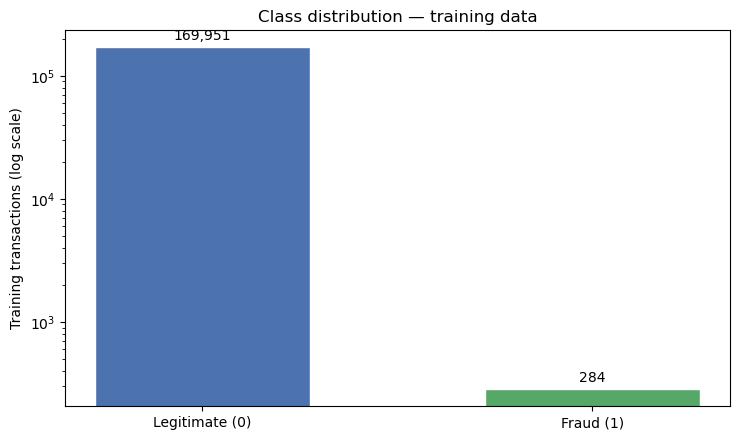

Always-legitimate baseline (training): 99.833% accuracy, 0% fraud recall


In [6]:
# A log scale lets me see the small fraud bar without hiding the larger class.
train_counts = y_train.value_counts().reindex([0, 1], fill_value=0)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
bars = ax.bar(
    ["Legitimate (0)", "Fraud (1)"],
    train_counts.values,
    color=[PRIMARY, SECONDARY],
    edgecolor="white",
    width=0.55,
)
ax.set_yscale("log")
ax.set_ylabel("Training transactions (log scale)")
ax.set_title("Class distribution — training data")

for bar, count in zip(bars, train_counts.values):
    ax.annotate(
        f"{count:,}",
        (bar.get_x() + bar.get_width() / 2, count),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
    )

plt.tight_layout()
plt.show()

naive_accuracy_train = (y_train == 0).mean()
print(f"Always-legitimate baseline (training): {naive_accuracy_train:.3%} accuracy, 0% fraud recall")


**Why I don't use accuracy alone:** The large blue bar is real, but it tells me more about class imbalance than model quality. Missing every fraud case would still give a very high accuracy score.

### 5.2 Distribution, skewness, median, and IQR

I use a few robust summary statistics to understand the distributions:

- **Mean vs. median:** A few very large values can pull the mean upward; the median is more resistant.
- **Skewness:** Positive skew means a long right tail; financial amounts often show this pattern.
- **Interquartile range (IQR):** Q3 − Q1 describes the spread of the middle 50% without being dominated by extremes.
- **Log transformation:** `log(1 + Amount)` compresses large values for **visualization**. It does not change the model input in this notebook.

`Time / 3600` measures **elapsed hours since the first recorded transaction**; it is not the local hour of day.

In [7]:
train_df = X_train.copy()
train_df["Class"] = y_train

amount_stats = X_train["Amount"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]
)
amount_iqr = amount_stats["75%"] - amount_stats["25%"]
amount_skew = X_train["Amount"].skew()

stats_table = pd.DataFrame({
    "Statistic": [
        "Mean", "Median", "IQR", "95th percentile",
        "99th percentile", "Skewness",
    ],
    "Amount": [
        amount_stats["mean"], amount_stats["50%"], amount_iqr,
        amount_stats["95%"], amount_stats["99%"], amount_skew,
    ],
})
display(stats_table.style.format({"Amount": "{:,.3f}"}))


,Statistic,Amount
0,Mean,88.161
1,Median,22.040
2,IQR,71.895
3,95th percentile,363.216
4,99th percentile,"1,011.155"
5,Skewness,15.196


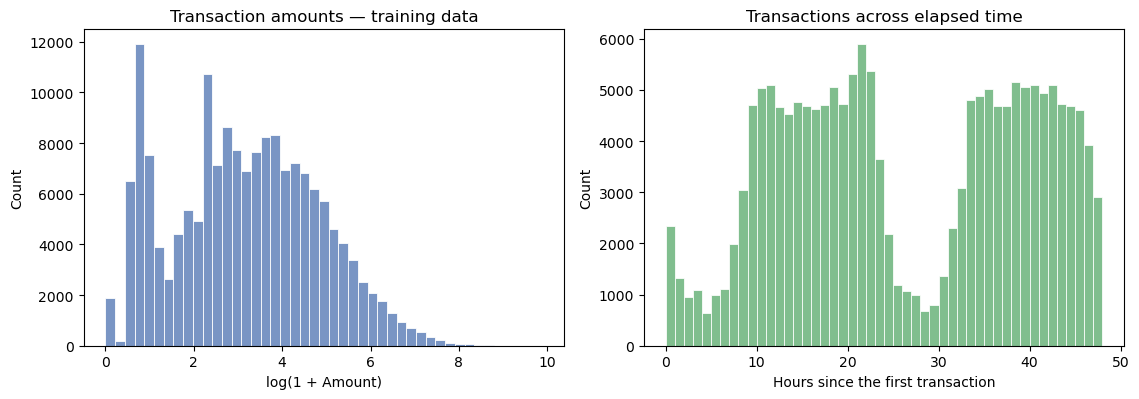

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.1))

# The log transform is just for the amount chart, not for model training.
amount_for_plot = np.log1p(X_train["Amount"].clip(lower=0).dropna())
sns.histplot(amount_for_plot, bins=45, color=PRIMARY, edgecolor="white", ax=axes[0])
axes[0].set(
    title="Transaction amounts — training data",
    xlabel="log(1 + Amount)",
    ylabel="Count",
)

elapsed_hours = X_train["Time"].dropna() / 3600
sns.histplot(elapsed_hours, bins=48, color=SECONDARY, edgecolor="white", ax=axes[1])
axes[1].set(
    title="Transactions across elapsed time",
    xlabel="Hours since the first transaction",
    ylabel="Count",
)

plt.tight_layout()
plt.show()


The amount distribution is heavily right-skewed. I used a log view to make the chart readable, but I did **not** log-transform the model's input. `Time` is elapsed time, not the hour of day.

### 5.3 Correlation with a binary target

Pearson correlation measures *linear association*. When one variable is binary (0/1), this is also related to the **point-biserial correlation**. A strong correlation can be a useful clue, but:

- it does **not** establish causation;
- it does **not** measure every nonlinear relationship;
- anonymized `V` features cannot be translated into business causes.

I rank correlations by **absolute magnitude**, while preserving the sign in the chart.

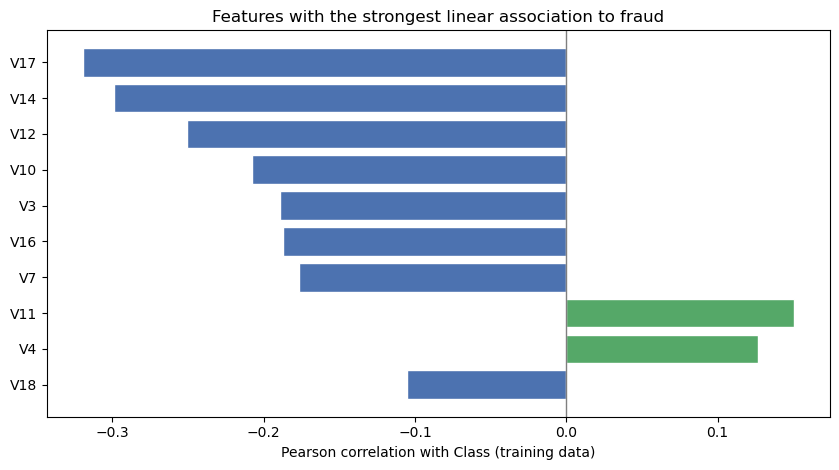

In [9]:
# Select features using training data only; keep the sign when plotting.
correlations = train_df.corr(numeric_only=True)["Class"].drop("Class")
top_correlations = correlations.reindex(
    correlations.abs().nlargest(10).index
)
ordered = top_correlations.iloc[::-1]
bar_colors = [SECONDARY if value >= 0 else PRIMARY for value in ordered]

fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.barh(ordered.index, ordered.values, color=bar_colors, edgecolor="white")
ax.axvline(0, color=NEUTRAL, linewidth=1)
ax.set(
    xlabel="Pearson correlation with Class (training data)",
    title="Features with the strongest linear association to fraud",
)
plt.tight_layout()
plt.show()


In [10]:
corr_table = top_correlations.rename("Pearson r with Class").to_frame()
corr_table["Fraud tends to have"] = np.where(
    corr_table["Pearson r with Class"] < 0, "lower values", "higher values"
)
display(corr_table.round(3))


,Pearson r with Class,Fraud tends to have
V17,-0.320,lower values
V14,-0.299,lower values
V12,-0.251,lower values
V10,-0.208,lower values
V3,-0.189,lower values
V16,-0.187,lower values
V7,-0.177,lower values
V11,0.151,higher values
V4,0.127,higher values
V18,-0.105,lower values


A negative correlation means that, linearly, fraud transactions tend to sit at *lower* values of that component, and a positive one means *higher* values. The sign tells me the direction of the difference, while the size only tells me how strongly a straight-line relationship shows up. Several of these components appear together at the top, so no single one is likely to do all the work; the models below can combine them.


### A closer look: correlation heatmap

The bar chart shows each feature's relationship with fraud. This heatmap adds another question: **how do the selected features relate to one another?**

I use the six strongest target-associated features from the **training set** plus `Class`. The colors follow my portfolio palette: **blue = negative**, **light gray = near zero**, and **green = positive**. A correlation of 1 on the diagonal simply means a variable is perfectly correlated with itself.

I hide the repeated upper triangle so each feature pair is shown once.

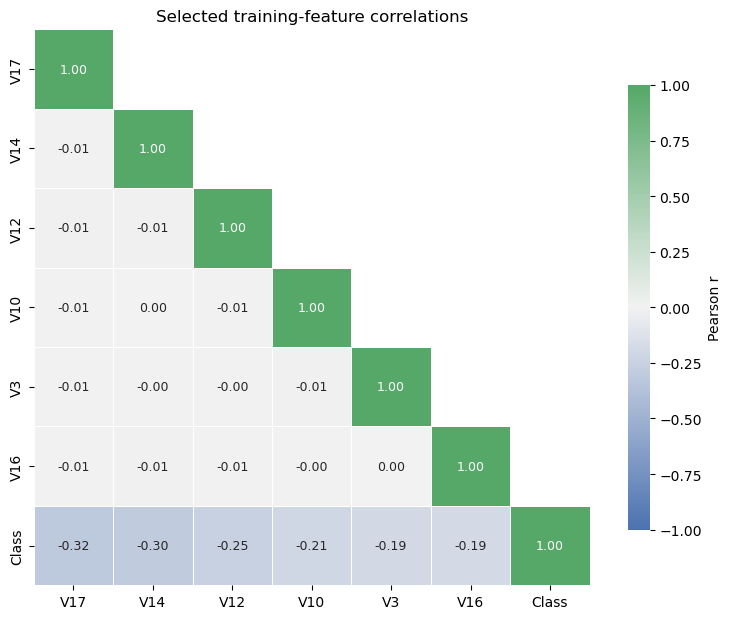

In [11]:
heatmap_columns = [*top_correlations.head(6).index, "Class"]
heatmap_corr = train_df[heatmap_columns].corr(numeric_only=True)

# Hide duplicate correlations above the diagonal.
heatmap_mask = np.triu(np.ones_like(heatmap_corr, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(8.0, 6.3))
sns.heatmap(
    heatmap_corr,
    mask=heatmap_mask,
    cmap=correlation_cmap,
    vmin=-1,
    vmax=1,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"label": "Pearson r", "shrink": 0.8},
    annot_kws={"fontsize": 9},
    ax=ax,
)
ax.set_title("Selected training-feature correlations")
plt.tight_layout()
plt.show()


In [12]:
feature_corr = heatmap_corr.drop(index="Class", columns="Class")
off_diagonal = feature_corr.where(~np.eye(len(feature_corr), dtype=bool)).abs()
class_corr = heatmap_corr["Class"].drop("Class").abs()
print(f"Largest |correlation| between two of the selected features: {np.nanmax(off_diagonal.values):.2f}")
print(f"Smallest |correlation| with Class among the selected features: {class_corr.min():.2f}")


Largest |correlation| between two of the selected features: 0.01
Smallest |correlation| with Class among the selected features: 0.19


**How I read the heatmap:** `V1`–`V28` are principal components, which PCA constructs to be uncorrelated with each other (on the data it was fitted to, i.e. the full dataset before my split). So I expect small values between the selected features, and the printed maximum lets me check that. The informative part is therefore the `Class` row: it shows how strongly each component is linearly related to fraud. Correlations this weak between features also mean the components are not simply repeating each other's information. This is a linear, one-feature-at-a-time view, so a feature with a modest correlation can still be useful to a tree model.


### 5.4 Outliers and robust comparisons

An observation beyond 1.5 × IQR from a quartile is often flagged as a potential outlier. It is a **screening rule**, not an instruction to delete the row.

Here I use the rule as a comparison rather than a cleaning step. I compute the fences from the **legitimate** training transactions and ask how often each class falls outside them, for the two features with the strongest correlation with `Class` (chosen on training data in Section 5.3). If fraud falls outside the legitimate fences much more often than legitimate transactions do, that feature separates the classes. It also shows why deleting "outliers" in fraud data would remove exactly the signal the model needs.

For readable boxplots I display a reproducible sample of legitimate transactions next to all training fraud transactions. The boxplots hide extreme dots (`showfliers=False`), but **no training rows are filtered**, and the table is computed on all training rows. Blue represents legitimate transactions and green represents fraud, as in the class-distribution chart.


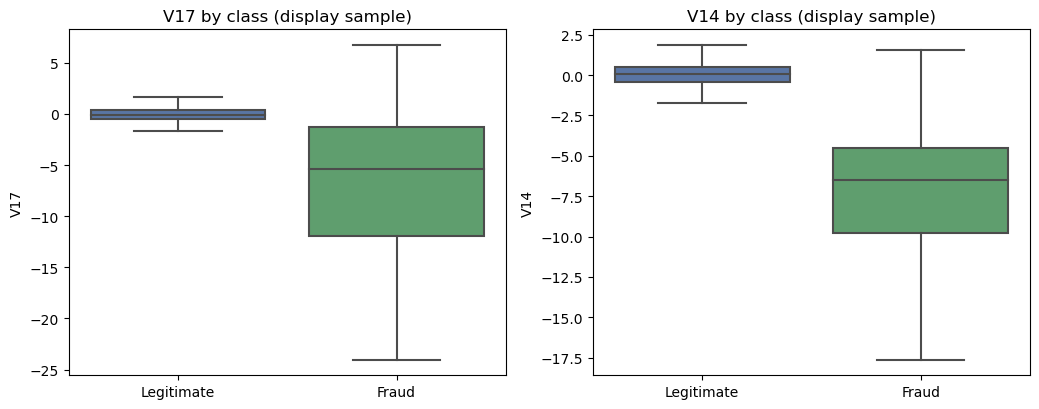

In [13]:
normal_train = train_df.loc[train_df["Class"] == 0]
fraud_train = train_df.loc[train_df["Class"] == 1]

# The two features with the strongest |correlation| with Class (training data only).
box_features = list(top_correlations.index[:2])

# A manageable display sample keeps the boxplots readable; model data stay intact.
normal_sample = normal_train.sample(
    n=min(2_000, len(normal_train)), random_state=RANDOM_STATE
)
eda_sample = pd.concat([normal_sample, fraud_train], ignore_index=True)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
for ax, feature in zip(axes, box_features):
    sns.boxplot(
        data=eda_sample,
        x="Class",
        y=feature,
        hue="Class",
        palette={0: PRIMARY, 1: SECONDARY},
        dodge=False,
        showfliers=False,
        ax=ax,
    )
    if ax.get_legend() is not None:
        ax.get_legend().remove()
    ax.set_xticks([0, 1], labels=["Legitimate", "Fraud"])
    ax.set(title=f"{feature} by class (display sample)", xlabel="")

plt.tight_layout()
plt.show()

# Exact shares on ALL training rows: fences come from the legitimate class.
fence_rows = []
for feature in box_features:
    q1, q3 = normal_train[feature].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    for label, subset in [("Legitimate", normal_train), ("Fraud", fraud_train)]:
        outside = ((subset[feature] < low) | (subset[feature] > high)).mean()
        fence_rows.append({
            "Feature": feature,
            "Class": label,
            "Share outside legitimate 1.5×IQR fences": outside,
        })

fence_table = pd.DataFrame(fence_rows).set_index(["Feature", "Class"])
display(fence_table.style.format("{:.1%}"))


The table gives the exact share of each class outside the legitimate-class fences, and the boxplots show how the middle 50% of each class differs. These are descriptive comparisons on training data, not a significance test, and the legitimate class is sampled **only for the figure**. All training rows are kept when fitting the models. Because the `V` features are anonymized, I avoid attaching business meanings to them.


## 6. The algorithm: how Random Forest works

### From a decision tree to a forest

A **decision tree** splits the data using questions such as “Is `V14` below a threshold?” until it reaches leaves that contain training observations. A common split criterion is **Gini impurity**:

$$ Gini = 1 - \sum_{k=1}^{K} p_k^2 $$

For binary classification, a pure node (all 0 or all 1) has Gini = 0. A balanced 50/50 node has Gini = 0.5. For each candidate split, the tree computes the sample-weighted average Gini impurity of the two child nodes and chooses the split that lowers impurity the most compared with the parent node. When `class_weight` is set, those weights enter the calculation.

A **Random Forest** combines many trees:

1. Each tree is fitted on a bootstrap sample of the training rows (sampling with replacement).
2. At each split, it considers a random subset of features.
3. Predictions are aggregated across trees. In scikit-learn, `predict_proba` averages the class probabilities estimated by the individual trees, which gives a model score between 0 and 1.

This *bagging + feature randomness* reduces the dependence on any single tree, often improving stability. It does not automatically make the scores **well calibrated probabilities**.

**Parameters I chose for a practical baseline:**

| Parameter | Meaning | Value here |
|---|---|---|
| `n_estimators` | Number of trees | 150 |
| `min_samples_leaf` | Minimum training rows in a leaf | 2 |
| `max_features` | Candidate features per split | `sqrt` (default) |
| `class_weight` | More weight for the rare class | `balanced_subsample` |
| `random_state` | Reproducibility | 42 |

**Why class weights?** With severe imbalance, an error on a fraud case can be underrepresented in the training objective. `balanced_subsample` recalculates class weights for each tree's bootstrap sample. It is a modeling choice, not a guarantee of better recall.

### Why compare with Logistic Regression?

Logistic Regression is a simpler, linear probabilistic baseline. It uses a logistic link to map a linear score to a value between 0 and 1:

$$ P(y=1\mid x) = \frac{1}{1+e^{-(\beta_0+\beta^T x)}} $$

I scale inputs for Logistic Regression, while trees generally do not need feature scaling. Both pipelines fit their imputers **on training data only**, avoiding preprocessing leakage.

**Preprocessing notes:** The dataset has no missing values, so the median imputer is only a safeguard and changes nothing here. I use `Time` and `Amount` as they are. That is harmless for trees, but `Amount` is strongly right-skewed (skewness ≈ 15 in the saved run), so Logistic Regression might do better with a log transform. I did not tune that, which is one reason to read the baseline as a simple reference point rather than a best-effort linear model.


## 7. Fit the models and compare validation metrics

### Metrics worth understanding

| Metric | Definition | Practical question |
|---|---|---|
| **Precision** | TP / (TP + FP) | Of flagged transactions, how many are fraud? |
| **Recall** | TP / (TP + FN) | Of all fraud transactions, how many did we catch? |
| **F1** | 2 × Precision × Recall / (Precision + Recall) | How balanced are precision and recall at this threshold? |
| **Average precision (AP)** | Weighted average of precision over recall increments | How well does the model rank rare fraud cases across thresholds? |
| **ROC-AUC** | Area under TPR–FPR curve | How well are positive and negative cases ranked overall? |

**TP:** fraud correctly flagged; **FP:** legitimate transaction incorrectly flagged; **FN:** fraud missed; **TN:** legitimate transaction correctly ignored.

**Important distinction:** AP is commonly used as a summary of a precision–recall curve. It is not always numerically identical to a trapezoidal “PR-AUC.” I report **AP** by its exact name. Metrics at threshold 0.5 describe one operating point; AP and ROC-AUC summarize ranking across thresholds.

**Why ROC-AUC and AP can point to different winners:** In this validation run, Logistic Regression has the higher ROC-AUC, while Random Forest has the higher AP. ROC-AUC looks at true-positive and false-positive rates across thresholds; with so many legitimate transactions, even a small false-positive rate can still mean a lot of false alerts. AP focuses on precision as recall changes, which is closer to the fraud-alert trade-off I'm trying to understand. That's why I give AP and the precision–recall curve more weight here, without ignoring ROC-AUC.

**A caution about the 0.5 columns:** Logistic Regression uses `class_weight="balanced"`, which pushes its scores upward, so its 0.5 threshold sits at a very different operating point from the forest's. Comparing the two models only at 0.5 would not be like-for-like. I rely on AP and the precision–recall curve for the model comparison, and I show the actual alert counts in the next table.


In [14]:
# A simple baseline helps me judge whether the forest adds value.
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )),
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=150,
            min_samples_leaf=2,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
}

validation_probabilities = {}
validation_rows = []

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    probabilities = model.predict_proba(X_val)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    validation_probabilities[name] = probabilities
    validation_rows.append({
        "Model": name,
        "Average precision (AP)": average_precision_score(y_val, probabilities),
        "ROC-AUC": roc_auc_score(y_val, probabilities),
        "Precision @ 0.5": precision_score(y_val, predictions, zero_division=0),
        "Recall @ 0.5": recall_score(y_val, predictions, zero_division=0),
        "F1 @ 0.5": f1_score(y_val, predictions, zero_division=0),
    })

validation_table = pd.DataFrame(validation_rows).set_index("Model")
display(validation_table.round(4))

rf_ap = validation_table.loc["Random Forest", "Average precision (AP)"]
lr_ap = validation_table.loc["Logistic Regression", "Average precision (AP)"]


Training Logistic Regression...
Training Random Forest...


,Average precision (AP),ROC-AUC,Precision @ 0.5,Recall @ 0.5,F1 @ 0.5
Model,,,,,
Logistic Regression,0.7868,0.9790,0.0538,0.9043,0.1016
Random Forest,0.8742,0.9554,0.9186,0.8404,0.8778


In [15]:
count_rows = []
for name, probabilities in validation_probabilities.items():
    predictions = (probabilities >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, predictions, labels=[0, 1]).ravel()
    count_rows.append({
        "Model": name,
        "Fraud caught (TP)": int(tp),
        "Fraud missed (FN)": int(fn),
        "False alarms (FP)": int(fp),
        "Alerts per fraud caught": (tp + fp) / tp if tp else np.nan,
    })

display(pd.DataFrame(count_rows).set_index("Model").round(2))


,Fraud caught (TP),Fraud missed (FN),False alarms (FP),Alerts per fraud caught
Model,,,,
Logistic Regression,85,9,1494,18.58
Random Forest,79,15,7,1.09


Raw counts make the trade-off concrete. A model with high recall but very low precision finds fraud by flagging a large number of legitimate transactions, and each of those costs review time. "Alerts per fraud caught" is a simple workload measure: how many flagged transactions someone would have to look at for each real fraud case found.


### 7.1 Precision–recall curves and the rare-class baseline

The **precision–recall curve** shows how precision changes as the classifier tries to capture more positive cases. The horizontal reference line is the **fraud prevalence** in validation data: approximately the precision of a random ranking at that base rate.

When fraud is rare, the PR curve is often more informative than accuracy or ROC-AUC alone. A curve that stays higher as recall grows represents a better precision–recall trade-off.

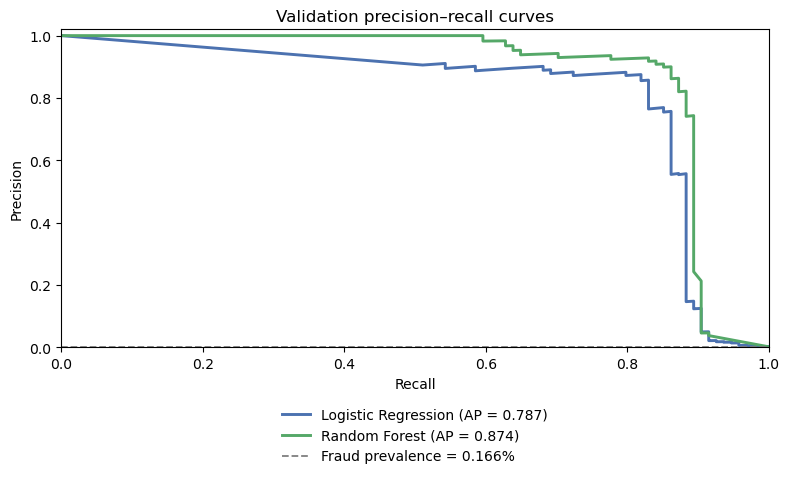

In [16]:
model_colors = {
    "Logistic Regression": PRIMARY,
    "Random Forest": SECONDARY,
}

fig, ax = plt.subplots(figsize=(8.0, 5.0))
for name, probabilities in validation_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_val, probabilities)
    ap = average_precision_score(y_val, probabilities)
    ax.plot(
        recall,
        precision,
        color=model_colors[name],
        linewidth=2.1,
        label=f"{name} (AP = {ap:.3f})",
    )

ax.axhline(
    y_val.mean(),
    color=NEUTRAL,
    linestyle="--",
    linewidth=1.3,
    label=f"Fraud prevalence = {y_val.mean():.3%}",
)
ax.set(
    xlabel="Recall",
    ylabel="Precision",
    xlim=(0, 1),
    ylim=(0, 1.02),
    title="Validation precision–recall curves",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)
plt.tight_layout()
plt.show()


**My reading:** In this validation sample, Random Forest has the higher AP and keeps precision high over a wide range of recall, while Logistic Regression has the higher ROC-AUC. For a rare class I care more about whether the alerts are useful than about one headline score, so I give the precision–recall curve more weight. I would still be careful about naming a winner: validation contains only 94 fraud cases and I used a single split, so a gap of this size could shrink or change with repeated validation or a time-based holdout.


## 8. Threshold analysis: a modeling decision with business consequences

A classifier can produce the same ranking of transactions while giving very different **alerts** depending on its threshold. Lowering the threshold generally flags more transactions: recall may improve, but the review team may receive more false alarms.

I use an **illustrative target of at least 80% validation recall**. Among validation thresholds meeting that target, I choose one with the highest precision (breaking ties toward the higher threshold). This is a transparent example of an operating preference, **not** a validated fraud-loss or bank policy.

The **test set does not participate in threshold selection**. The exact threshold is learned from validation predictions when this notebook runs.

In [17]:
rf_model = models["Random Forest"]
rf_val_prob = validation_probabilities["Random Forest"]
val_precision, val_recall, val_thresholds = precision_recall_curve(y_val, rf_val_prob)

TARGET_RECALL = 0.80

# The last PR-curve point has no threshold, so use [:-1] for precision/recall.
threshold_options = pd.DataFrame({
    "Threshold": val_thresholds,
    "Precision": val_precision[:-1],
    "Recall": val_recall[:-1],
})

# First meet the recall target, then choose the best precision.
valid_options = threshold_options[threshold_options["Recall"] >= TARGET_RECALL]
if valid_options.empty:
    raise RuntimeError("No validation threshold meets the recall target.")

best_precision = valid_options["Precision"].max()
# If precision is effectively tied, prefer the higher threshold.
best_options = valid_options[np.isclose(valid_options["Precision"], best_precision)]
chosen = best_options.sort_values("Threshold").iloc[-1]
selected_threshold = float(chosen["Threshold"])

threshold_summary = pd.DataFrame({
    "Value": [TARGET_RECALL, selected_threshold,
              float(chosen["Precision"]), float(chosen["Recall"])]
}, index=["Illustrative recall target", "Selected threshold",
          "Validation precision at threshold", "Validation recall at threshold"])
display(threshold_summary.round(4))


,Value
Illustrative recall target,0.8000
Selected threshold,0.5463
Validation precision at threshold,0.9286
Validation recall at threshold,0.8298


In [18]:
default_recall_val = recall_score(y_val, (rf_val_prob >= 0.5).astype(int))
print(f"Validation recall at the default 0.5 threshold: {default_recall_val:.3f} (target {TARGET_RECALL:.2f})")

# The selected value is itself one of the validation scores, so check how fragile it is.
lower_scores = rf_val_prob[rf_val_prob < selected_threshold]
if lower_scores.size:
    next_lower = float(lower_scores.max())
    midpoint = (selected_threshold + next_lower) / 2
    same_alerts = np.array_equal(rf_val_prob >= midpoint, rf_val_prob >= selected_threshold)
    print(f"Next lower validation score: {next_lower:.4f}")
    print(f"Any threshold in ({next_lower:.4f}, {selected_threshold:.4f}] gives the same validation alerts: {same_alerts}")
    print(f"Midpoint, a less sample-specific choice: {midpoint:.4f}")


Validation recall at the default 0.5 threshold: 0.840 (target 0.80)
Next lower validation score: 0.5460
Any threshold in (0.5460, 0.5463] gives the same validation alerts: True
Midpoint, a less sample-specific choice: 0.5462


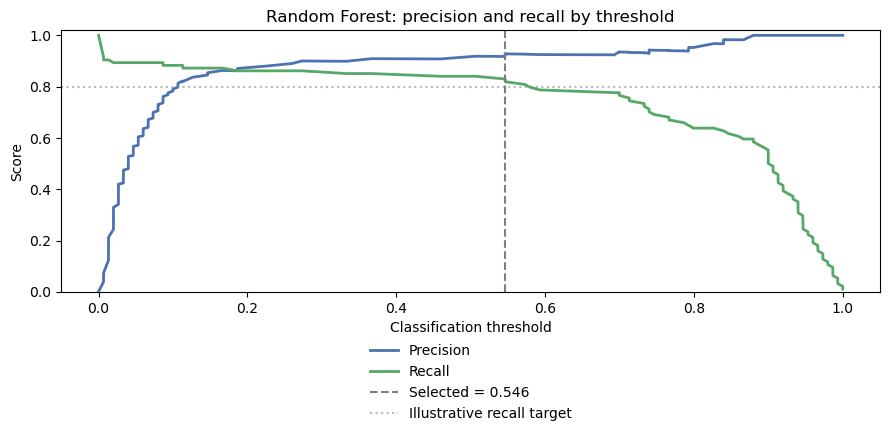

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(
    val_thresholds, val_precision[:-1],
    color=PRIMARY, label="Precision", linewidth=2,
)
ax.plot(
    val_thresholds, val_recall[:-1],
    color=SECONDARY, label="Recall", linewidth=2,
)
ax.axvline(
    selected_threshold, color=NEUTRAL, linestyle="--",
    label=f"Selected = {selected_threshold:.3f}",
)
ax.axhline(
    TARGET_RECALL, color=NEUTRAL, alpha=0.55, linestyle=":",
    label="Illustrative recall target",
)
ax.set(
    xlabel="Classification threshold",
    ylabel="Score",
    ylim=(0, 1.02),
    title="Random Forest: precision and recall by threshold",
)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False)
plt.tight_layout()
plt.show()


The selected threshold is only slightly above 0.5, and the printed check explains why that is not surprising. First, the default 0.5 threshold already meets my 80% recall target on validation, so the search changes very little. I am showing the **procedure**, not a large gain. Second, the selected value is exactly one of the validation scores, so it depends on that particular sample: any value between the next lower score and the selected one gives the same validation alerts, and the midpoint would be a less sample-specific choice.

In a real setting I would set the recall target from the cost of missed fraud versus review workload, and I would use cross-validation or a time-based holdout to see how stable the threshold is. The threshold here is an **example**, not a recommendation for a real fraud team.


## 9. Final evaluation on the untouched test set

I now apply the already-trained Random Forest to the held-out test data. I compare **the default threshold (0.5)** with **the validation-selected threshold**. These are two operating points of **the same model**, not two separately fitted models.

**What I look for:**

- **False negatives (FN):** fraud cases the model misses.
- **False positives (FP):** legitimate transactions that would be flagged.
- **Precision/recall/F1:** whether the alert workload and fraud coverage seem balanced.
- **Average precision:** ranking performance, independent of the chosen alert threshold.

The final test is a *check*, not a new opportunity to tune the threshold.

In [20]:
# Only now do I touch the held-out test set.
rf_test_prob = rf_model.predict_proba(X_test)[:, 1]
thresholds_to_compare = {
    "Default (0.5)": 0.5,
    "Validation-selected": selected_threshold,
}

test_predictions = {}
test_rows = []
for label, threshold in thresholds_to_compare.items():
    predictions = (rf_test_prob >= threshold).astype(int)
    test_predictions[label] = predictions
    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()

    test_rows.append({
        "Operating point": label,
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "False positives": int(fp),
        "False negatives": int(fn),
    })

test_table = pd.DataFrame(test_rows).set_index("Operating point")
display(test_table.round(4))

naive_accuracy = (y_test == 0).mean()
test_ap = average_precision_score(y_test, rf_test_prob)
test_roc_auc = roc_auc_score(y_test, rf_test_prob)
print(f"Always-legitimate test accuracy: {naive_accuracy:.3%}")
print(f"Random Forest test average precision (AP): {test_ap:.4f}")
print(f"Random Forest test ROC-AUC: {test_roc_auc:.4f}")


# Different thresholds can still flag exactly the same transactions.
same_test_predictions = np.array_equal(
    test_predictions["Default (0.5)"], test_predictions["Validation-selected"]
)
if same_test_predictions:
    print("Both thresholds produced the same test predictions in this run.")
else:
    print("The thresholds produced different test predictions; compare FP and FN above.")


,Threshold,Accuracy,Precision,Recall,F1,False positives,False negatives
Operating point,,,,,,,
Default (0.5),0.5000,0.9995,0.9714,0.7158,0.8242,2,27
Validation-selected,0.5463,0.9995,0.9714,0.7158,0.8242,2,27


Always-legitimate test accuracy: 99.833%
Random Forest test average precision (AP): 0.8149
Random Forest test ROC-AUC: 0.9338
Both thresholds produced the same test predictions in this run.


In [21]:
val_pred_sel = (rf_val_prob >= selected_threshold).astype(int)
test_pred_sel = test_predictions["Validation-selected"]

gap_table = pd.DataFrame({
    "Validation": {
        "Average precision": average_precision_score(y_val, rf_val_prob),
        "ROC-AUC": roc_auc_score(y_val, rf_val_prob),
        "Precision": precision_score(y_val, val_pred_sel, zero_division=0),
        "Recall": recall_score(y_val, val_pred_sel, zero_division=0),
    },
    "Test": {
        "Average precision": average_precision_score(y_test, rf_test_prob),
        "ROC-AUC": roc_auc_score(y_test, rf_test_prob),
        "Precision": precision_score(y_test, test_pred_sel, zero_division=0),
        "Recall": recall_score(y_test, test_pred_sel, zero_division=0),
    },
})
display(gap_table.round(4))
print(f"Fraud cases: {int(y_val.sum())} in validation vs {int(y_test.sum())} in test")

test_recall_value = gap_table.loc["Recall", "Test"]
if test_recall_value < TARGET_RECALL:
    print(f"Test recall ({test_recall_value:.1%}) is below the {TARGET_RECALL:.0%} validation target.")
else:
    print(f"Test recall ({test_recall_value:.1%}) meets the {TARGET_RECALL:.0%} validation target.")


,Validation,Test
Average precision,0.8742,0.8149
ROC-AUC,0.9554,0.9338
Precision,0.9286,0.9714
Recall,0.8298,0.7158


Fraud cases: 94 in validation vs 95 in test
Test recall (71.6%) is below the 80% validation target.


**Reading the validation–test gap:** The metrics do not all move in the same direction. Recall falls from **83.0% on validation to 71.6% on test**, while average precision (AP) falls from **0.874 to 0.815** and ROC-AUC also decreases. Precision, however, rises from **92.9% to 97.1%**: the model flags only **two legitimate test transactions**. Higher precision here does not cancel out the fraud cases the model misses.

There are fewer than 100 fraud cases in each split, so each missed case shifts recall by about one percentage point. I also compared models and chose the threshold using validation data, which can make the validation estimates somewhat optimistic. I therefore cannot claim that the illustrative **80% recall target** was achieved on the held-out test set.

### 9.1 Confusion matrix: where the mistakes happened

The matrix has **actual classes in rows** and **predicted classes in columns**. The top-right cell is a false alarm (FP), and the bottom-left is a missed fraud case (FN).

The classes are extremely imbalanced, so I shade each cell by its **share of the actual class** rather than by its raw count. The annotations still show the exact transaction counts. In this saved run, the default and validation-selected thresholds give identical test predictions, so one matrix is enough. If they differ when the notebook is rerun, the code displays both.

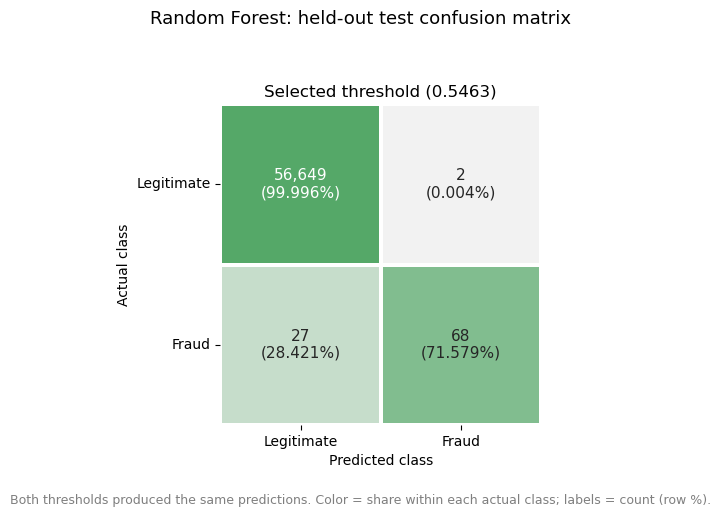

In [22]:
# If both thresholds produce the same alerts, one matrix is easier to read.
plot_items = (
    [("Validation-selected", test_predictions["Validation-selected"])]
    if same_test_predictions else list(test_predictions.items())
)
fig, axes = plt.subplots(1, len(plot_items), figsize=(6.8 * len(plot_items), 5.2))
axes = np.atleast_1d(axes)

for ax, (label, predictions) in zip(axes, plot_items):
    counts = confusion_matrix(y_test, predictions, labels=[0, 1])
    row_shares = counts / counts.sum(axis=1, keepdims=True)
    annotations = np.array([
        [f"{count:,}\n({share:.3%})" for count, share in zip(row, shares)]
        for row, shares in zip(counts, row_shares)
    ])

    sns.heatmap(
        row_shares, annot=annotations, fmt="", cmap=confusion_cmap,
        vmin=0, vmax=1, square=True, cbar=False,
        linewidths=1.5, linecolor="white", annot_kws={"fontsize": 11}, ax=ax,
    )
    ax.set(
        xlabel="Predicted class", ylabel="Actual class",
        title=(f"Selected threshold ({selected_threshold:.4f})"
               if label == "Validation-selected" else "Default threshold (0.5)"),
    )
    ax.set_xticklabels(["Legitimate", "Fraud"], rotation=0)
    ax.set_yticklabels(["Legitimate", "Fraud"], rotation=0)

fig.suptitle("Random Forest: held-out test confusion matrix", fontsize=13)
fig.text(
    0.5, 0.03,
    ("Both thresholds produced the same predictions. " if same_test_predictions else "")
    + "Color = share within each actual class; labels = count (row %).",
    ha="center", fontsize=9, color=NEUTRAL,
)
fig.tight_layout(rect=(0, 0.07, 1, 0.93))
plt.show()

The forest caught **68 of 95 fraud cases** and missed **27**. It also flagged **2 legitimate transactions**. The default and validation-selected thresholds produced the same alerts in this test split: no test score fell between 0.5 and the selected threshold. The percentages in the plot are calculated separately within each actual class, so the small fraud row is not washed out by the much larger legitimate row.

### 9.2 Classification report: why macro and weighted averages differ

`support` is the number of true observations in each class. A **macro average** gives both classes equal weight; a **weighted average** is dominated by the common class. For imbalanced data, I read the **fraud row first** instead of treating the weighted average as the main result.

In [23]:
print("Classification report — validation-selected threshold (held-out test)")
print(classification_report(
    y_test, test_predictions["Validation-selected"],
    target_names=["Legitimate", "Fraud"], zero_division=0
))

Classification report — validation-selected threshold (held-out test)
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56651
       Fraud       0.97      0.72      0.82        95

    accuracy                           1.00     56746
   macro avg       0.99      0.86      0.91     56746
weighted avg       1.00      1.00      1.00     56746



### 9.3 Optional deeper dive: statistical uncertainty in fraud recall

Recall is estimated from a finite number of actual fraud cases. Even if the dataset is large overall, the positive-class sample may be small.

I use a **Wilson 95% interval** for the proportion of fraud cases caught. This is an approximate binomial interval under independent, identically distributed observations; it does **not** account for time drift, correlated transactions, or dataset selection bias.

For $\hat p = TP/(TP+FN)$, positive-class sample size $n$, and $z=1.96$, the Wilson interval adjusts the center and margin to behave better than a simple normal interval near 0 or 1.

This section is optional for following the modeling workflow, but I keep it because a point estimate alone does not show sampling uncertainty.

In [24]:
def wilson_interval(successes, trials, z=1.96):
    if trials == 0:
        return (np.nan, np.nan)
    p = successes / trials
    denom = 1 + z*z/trials
    center = (p + z*z/(2*trials)) / denom
    half_width = (z/denom) * np.sqrt(p*(1-p)/trials + z*z/(4*trials*trials))
    return center - half_width, center + half_width

chosen_pred = test_predictions["Validation-selected"]
tn, fp, fn, tp = confusion_matrix(y_test, chosen_pred, labels=[0, 1]).ravel()
ci_low, ci_high = wilson_interval(int(tp), int(tp+fn))
interval_table = pd.DataFrame({
    "Metric": ["Fraud cases in test", "Fraud cases caught", "Recall", "Approx. 95% Wilson CI"],
    "Value": [f"{tp+fn:,}", f"{tp:,}", f"{tp/(tp+fn):.1%}",
              f"{ci_low:.1%} to {ci_high:.1%}"]
})
display(interval_table)


,Metric,Value
0,Fraud cases in test,95
1,Fraud cases caught,68
2,Recall,71.6%
3,Approx. 95% Wilson CI,61.8% to 79.7%


In [25]:
if ci_high < TARGET_RECALL:
    print(f"The upper end of the interval ({ci_high:.1%}) is below the {TARGET_RECALL:.0%} target, so the target is not supported on the test set.")
elif ci_low > TARGET_RECALL:
    print(f"The whole interval ({ci_low:.1%} to {ci_high:.1%}) is above the {TARGET_RECALL:.0%} target.")
else:
    print(f"The interval ({ci_low:.1%} to {ci_high:.1%}) contains the {TARGET_RECALL:.0%} target, so the test set is inconclusive about it.")


The upper end of the interval (79.7%) is below the 80% target, so the target is not supported on the test set.


The interval describes sampling uncertainty in recall for these fraud cases only. It does not include the extra uncertainty from tuning the threshold on validation or from fraud patterns changing over time, so the real uncertainty is larger than the interval suggests.


## 10. Which features matter to Random Forest?

The forest provides **impurity-based feature importances**, measuring how much splits on each feature reduce impurity across the fitted trees. They help me understand the model's internal behavior, but they are **not causal effects**.

These importances can favor features with more potential split points, and anonymized PCA features limit business interpretation. A more rigorous follow-up would be permutation importance on validation data, with awareness of correlated features.

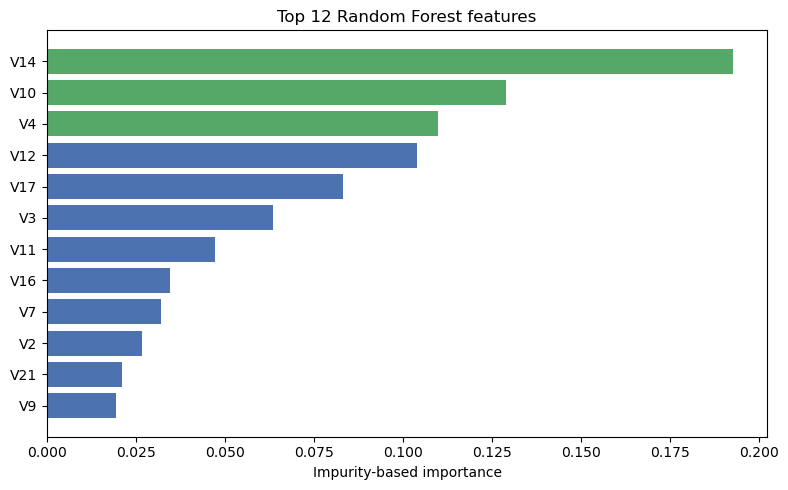

In [26]:
forest = rf_model.named_steps["classifier"]
importances = pd.Series(
    forest.feature_importances_,
    index=X_train.columns,
)
top_importances = importances.nlargest(12).sort_values()

# Green highlights the three highest impurity-based importance scores.
top_three = set(importances.nlargest(3).index)
bar_colors = [SECONDARY if feature in top_three else PRIMARY
              for feature in top_importances.index]

fig, ax = plt.subplots(figsize=(8.0, 5.0))
ax.barh(top_importances.index, top_importances.values, color=bar_colors)
ax.set(
    xlabel="Impurity-based importance",
    title="Top 12 Random Forest features",
)
plt.tight_layout()
plt.show()

In [27]:
rank_table = pd.DataFrame({
    "Importance": importances,
    "|r| with Class": correlations.abs().reindex(importances.index),
})
rank_table["Importance rank"] = rank_table["Importance"].rank(ascending=False).astype(int)
rank_table["|r| rank"] = rank_table["|r| with Class"].rank(ascending=False).astype(int)
display(rank_table.sort_values("Importance", ascending=False).head(10).round(4))


,Importance,|r| with Class,Importance rank,|r| rank
V14,0.1927,0.2987,1,2
V10,0.1290,0.2080,2,4
V4,0.1099,0.1269,3,9
V12,0.1040,0.2507,4,3
V17,0.0832,0.3197,5,1
V3,0.0635,0.1890,6,5
V11,0.0471,0.1507,7,8
V16,0.0346,0.1871,8,6
V7,0.0322,0.1769,9,7
V2,0.0267,0.0855,10,14


The table compares the forest's impurity-based ranking with the ranking by absolute linear correlation from Section 5.3. Features near the top of both lists are consistent evidence that they carry signal. Differences are expected, because correlation measures only a one-feature linear relationship, while trees can use nonlinear effects and interactions. Neither ranking establishes a cause of fraud, and the anonymized PCA features cannot be translated into business meaning.


## 11. What I learned

**Accuracy was the wrong place to start.** With fraud this rare, an always-legitimate prediction would be correct almost every time and still catch no fraud. Precision, recall, and the actual alert counts gave me a much clearer picture.

**The models made different trade-offs.** On validation, Random Forest had higher average precision than Logistic Regression (0.874 vs. 0.788), although Logistic Regression had higher ROC-AUC. At the default 0.5 threshold, Logistic Regression caught 85 of 94 fraud cases but raised 1,494 false alarms; Random Forest caught 79 and raised 7. Because the models use different class-weighting strategies, I would not judge them by their 0.5 thresholds alone.

**The test set changed my interpretation.** The validation-selected Random Forest threshold reached about 83% recall on validation, but only **68 of 95 fraud cases (71.6%)** were caught on the held-out test set. It missed 27 cases and flagged just 2 legitimate transactions, giving **97.1% precision**. The selected threshold and the default 0.5 threshold happened to produce identical test predictions. That is possible when no test score falls between them.

**There is real uncertainty behind those percentages.** The approximate 95% Wilson interval for test recall was **61.8%–79.7%**. It describes sampling uncertainty for this set of fraud cases, not the uncertainty from changing fraud patterns or the earlier model and threshold choices. I therefore cannot claim that the illustrative 80% recall target was achieved on unseen data.

### Limitations I would keep in mind

- This is a **random split of historical transactions**. An out-of-time test would be more informative about future fraud patterns.
- Removing exact duplicate rows also removed 19 fraud rows. Without transaction identifiers, I cannot tell whether they represented distinct real transactions.
- Logistic Regression is a basic reference model here, not an optimized alternative; its raw `Amount` input and balanced class weights affect the comparison.
- The anonymized PCA features limit business interpretation, and the forest's feature importances are **not causal explanations**.

### What I would try next

I would start with a time-based holdout, then test whether the threshold remains stable across different validation samples. I would also examine probability calibration and the business cost of false alarms versus missed fraud. I **have not systematically tuned the Random Forest**; a small cross-validation search on the training data would be a reasonable next experiment.

---

**To reproduce this notebook:** Download the [ULB credit card fraud dataset](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). On Kaggle, attach it using **Add Input**; locally, put `creditcard.csv` beside the notebook or in `data/`. Run the cells from top to bottom. The CSV is not bundled with this file.

**Tools:** Python, pandas, NumPy, scikit-learn, Matplotlib, seaborn.


## Portfolio profiles

Here are a few links to my other data science projects and profiles:

- **GitHub profile:** [AnahitaPouladi](https://github.com/anahitapouladi/credit-card-fraud-detection-random-forest)
- **Kaggle notebooks:** [anahitapouladi](https://www.kaggle.com/code/anahitapouladi/credit-card-fraud-detection-random-forest)
